In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.13 (main, Jun  5 2025, 08:21:08) [Clang 14.0.6 ]
Python executable: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/.venv/bin/python


# Phase 5: Feature Engineering and Feature Selection

## Bank Marketing Subscription Prediction

### Objective
Improve the predictive information available to machine learning models through meaningful feature engineering and systematic feature selection.

### Project Goals
- Investigate and engineer candidate features.
- Evaluate the usefulness of each engineered feature.
- Perform correlation analysis and Mutual Information.
- Analyze Random Forest feature importance.
- Evaluate permutation importance and Recursive Feature Elimination (RFE).
- Compare feature sets using validation performance.
- Prevent data leakage throughout the experimentation process.

### Leakage Prevention
- The `duration` feature is excluded because it is only known after the last contact call.
- The target variable `y` must never be included in input features.
- Data-dependent transformations and feature selection must be fitted using training data only.
- Validation data must remain separate from feature-selection fitting.

### Dataset
- Source: `data/processed/cleaned_data.csv`
- Total observations: 4,521
- Original columns: 17
- Target variable: `y`
- Prediction type: Binary classification

## 1. Import Libraries and Configure the Experiment

This section imports the libraries required for feature engineering, statistical analysis, feature selection, model training and evaluation.

In [2]:
# Core libraries
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Feature selection
from sklearn.feature_selection import (
    mutual_info_classif,
    RFE,
)

# Machine learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Correct project root
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

# Project paths
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"

IMAGE_PATH = PROJECT_ROOT / "images" / "feature_engineering"
IMAGE_PATH.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Figure directory:", IMAGE_PATH)
print("Random state:", RANDOM_STATE)

Libraries imported successfully.
Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
Dataset path: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/data/processed/cleaned_data.csv
Dataset exists: True
Figure directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/feature_engineering
Random state: 42


## 2. Load and Validate the Dataset

Load the cleaned Bank Marketing dataset and verify its dimensions, schema, target distribution, missing values and duplicate records before feature engineering.

In [3]:
# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Dataset overview
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["y"].value_counts())

print("\nTarget percentage:")
display(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)

# Leakage-related verification
print("\nDuration column present:", "duration" in df.columns)
print("Target column:", "y")

Dataset shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


Missing values:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


Duplicate records: 0

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64


Target percentage:


y
no     88.48
yes    11.52
Name: proportion, dtype: float64


Duration column present: True
Target column: y


## 3. Baseline Model and Experimental Setup

Before introducing engineered features, establish a baseline model using the original predictive features.

### Experimental methodology
- Training-validation split: 80:20.
- Stratification: Preserve the target class distribution.
- Random state: 42.
- Baseline estimator: Logistic Regression.
- Imbalance handling: SMOTENC applied only to training data.
- Numerical preprocessing: StandardScaler.
- Categorical preprocessing: OneHotEncoder.

### Evaluation metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

The baseline results will serve as the reference for evaluating engineered and selected feature sets.

In [4]:
# Import reusable preprocessing utilities
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    split_features_target,
    split_data,
    build_smotenc_model_pipeline,
    NUMERICAL_FEATURES,
    CATEGORICAL_FEATURES,
)

# Separate original features and target
X, y = split_features_target(df)

print("Original predictive feature shape:", X.shape)
print("Target shape:", y.shape)

# Confirm duration and target are excluded
assert "duration" not in X.columns
assert "y" not in X.columns

print("\nDuration excluded:", "duration" not in X.columns)
print("Target excluded:", "y" not in X.columns)

# Stratified train-validation split
X_train, X_valid, y_train, y_valid = split_data(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print("\nTraining feature shape:", X_train.shape)
print("Validation feature shape:", X_valid.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(4))

print("\nValidation target distribution:")
display(y_valid.value_counts(normalize=True).round(4))

# Build baseline model using the Phase 3 pipeline
baseline_model = build_smotenc_model_pipeline(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    random_state=RANDOM_STATE,
)

# Train only on training data
baseline_model.fit(X_train, y_train)

# Validation predictions
y_pred = baseline_model.predict(X_valid)
y_prob = baseline_model.predict_proba(X_valid)[:, 1]

# Evaluate baseline
baseline_results = {
    "Accuracy": accuracy_score(y_valid, y_pred),
    "Precision": precision_score(y_valid, y_pred, zero_division=0),
    "Recall": recall_score(y_valid, y_pred, zero_division=0),
    "F1 Score": f1_score(y_valid, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_valid, y_prob),
    "PR-AUC": average_precision_score(y_valid, y_prob),
}

baseline_metrics = pd.DataFrame(
    [baseline_results],
    index=["Baseline Logistic Regression"]
)

print("\nBASELINE VALIDATION RESULTS")
display(baseline_metrics.round(4))

print("\nClassification report:")
print(classification_report(
    y_valid,
    y_pred,
    target_names=["No Subscription", "Subscription"],
    zero_division=0,
))

print("\nConfusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_valid, y_pred),
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"],
))

Original predictive feature shape: (4521, 15)
Target shape: (4521,)

Duration excluded: True
Target excluded: True

Training feature shape: (3616, 15)
Validation feature shape: (905, 15)

Training target distribution:


y
0    0.8847
1    0.1153
Name: proportion, dtype: float64


Validation target distribution:


y
0    0.8851
1    0.1149
Name: proportion, dtype: float64


BASELINE VALIDATION RESULTS


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Baseline Logistic Regression,0.6707,0.1891,0.5673,0.2837,0.688,0.2899



Classification report:
                 precision    recall  f1-score   support

No Subscription       0.92      0.68      0.79       801
   Subscription       0.19      0.57      0.28       104

       accuracy                           0.67       905
      macro avg       0.56      0.63      0.53       905
   weighted avg       0.84      0.67      0.73       905


Confusion matrix:


,Predicted No,Predicted Yes
Actual No,548,253
Actual Yes,45,59


## 4. Candidate Feature Engineering

Five candidate features are investigated:

1. age_group
2. balance_group
3. has_previous_contact
4. total_contacts
5. campaign_intensity

Original features are retained so that the engineered features can be compared against the baseline.

Balance segmentation thresholds are learned exclusively from the training dataset and reused for validation data.

The duration feature remains excluded from all predictive feature sets.

In [5]:
# Preserve original feature sets
X_train_engineered = X_train.copy()
X_valid_engineered = X_valid.copy()

# --------------------------------------------------
# 1. AGE GROUP
# Fixed age boundaries based on the investigated
# age distribution.
# --------------------------------------------------

AGE_BINS = [18, 30, 40, 50, 60, np.inf]

AGE_LABELS = [
    "18-30",
    "31-40",
    "41-50",
    "51-60",
    "60+",
]

def create_age_group(data):
    return pd.cut(
        data["age"],
        bins=AGE_BINS,
        labels=AGE_LABELS,
        include_lowest=True,
    ).astype(str)


X_train_engineered["age_group"] = create_age_group(
    X_train_engineered
)

X_valid_engineered["age_group"] = create_age_group(
    X_valid_engineered
)

# --------------------------------------------------
# 2. BALANCE GROUP
# Learn positive-balance thresholds from training
# data only.
# --------------------------------------------------

positive_balances = X_train_engineered.loc[
    X_train_engineered["balance"] > 0,
    "balance"
]

BALANCE_MEDIAN = positive_balances.median()
BALANCE_Q90 = positive_balances.quantile(0.90)

def create_balance_group(data):
    conditions = [
        data["balance"] < 0,
        data["balance"] == 0,
        (data["balance"] > 0) &
        (data["balance"] <= BALANCE_MEDIAN),
        (data["balance"] > BALANCE_MEDIAN) &
        (data["balance"] <= BALANCE_Q90),
        data["balance"] > BALANCE_Q90,
    ]

    labels = [
        "negative",
        "zero",
        "positive_low",
        "positive_medium",
        "positive_high",
    ]

    return pd.Series(
        np.select(conditions, labels, default="unknown"),
        index=data.index,
        dtype="str",
    )


X_train_engineered["balance_group"] = create_balance_group(
    X_train_engineered
)

X_valid_engineered["balance_group"] = create_balance_group(
    X_valid_engineered
)

# --------------------------------------------------
# 3. HAS PREVIOUS CONTACT
# --------------------------------------------------

def create_previous_contact(data):
    return (data["pdays"] != -1).astype(int)


X_train_engineered["has_previous_contact"] = (
    create_previous_contact(X_train_engineered)
)

X_valid_engineered["has_previous_contact"] = (
    create_previous_contact(X_valid_engineered)
)

# --------------------------------------------------
# 4. TOTAL CONTACTS
# --------------------------------------------------

X_train_engineered["total_contacts"] = (
    X_train_engineered["campaign"] +
    X_train_engineered["previous"]
)

X_valid_engineered["total_contacts"] = (
    X_valid_engineered["campaign"] +
    X_valid_engineered["previous"]
)

# --------------------------------------------------
# 5. CAMPAIGN INTENSITY
# --------------------------------------------------

CAMPAIGN_BINS = [0, 2, 5, np.inf]

CAMPAIGN_LABELS = [
    "low",
    "medium",
    "high",
]

def create_campaign_intensity(data):
    return pd.cut(
        data["campaign"],
        bins=CAMPAIGN_BINS,
        labels=CAMPAIGN_LABELS,
        include_lowest=True,
    ).astype(str)


X_train_engineered["campaign_intensity"] = (
    create_campaign_intensity(X_train_engineered)
)

X_valid_engineered["campaign_intensity"] = (
    create_campaign_intensity(X_valid_engineered)
)

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

ENGINEERED_FEATURES = [
    "age_group",
    "balance_group",
    "has_previous_contact",
    "total_contacts",
    "campaign_intensity",
]

print("ENGINEERED FEATURES CREATED SUCCESSFULLY")

print("\nBalance thresholds learned from training data:")
print("Positive balance median:", BALANCE_MEDIAN)
print("Positive balance 90th percentile:", BALANCE_Q90)

print("\nTraining feature shape:", X_train_engineered.shape)
print("Validation feature shape:", X_valid_engineered.shape)

print("\nNew feature distributions in training data:")

for feature in ENGINEERED_FEATURES:
    print(f"\n{feature}")
    display(X_train_engineered[feature].value_counts(dropna=False))

print("\nNew feature distributions in validation data:")

for feature in ENGINEERED_FEATURES:
    print(f"\n{feature}")
    display(X_valid_engineered[feature].value_counts(dropna=False))

# Leakage checks
assert "duration" not in X_train_engineered.columns
assert "y" not in X_train_engineered.columns

assert X_train_engineered.index.equals(y_train.index)
assert X_valid_engineered.index.equals(y_valid.index)

assert X_train_engineered[ENGINEERED_FEATURES].notna().all().all()
assert X_valid_engineered[ENGINEERED_FEATURES].notna().all().all()

print("\nAll five features created.")
print("No target leakage detected in feature columns.")
print("Training and validation indices preserved.")

ENGINEERED FEATURES CREATED SUCCESSFULLY

Balance thresholds learned from training data:
Positive balance median: 668.0
Positive balance 90th percentile: 4375.200000000002

Training feature shape: (3616, 20)
Validation feature shape: (905, 20)

New feature distributions in training data:

age_group


age_group
31-40    1447
41-50     937
51-60     630
18-30     508
60+        94
Name: count, dtype: int64


balance_group


balance_group
positive_low       1515
positive_medium    1211
positive_high       303
negative            302
zero                285
Name: count, dtype: int64


has_previous_contact


has_previous_contact
0    2947
1     669
Name: count, dtype: int64

... (11 outputs left out)

total_contacts
1     270
2     254
3     121
4      80
5      43
6      37
7      22
8      18
9      10
13      9
10      9
11      7
12      7
16      3
14      3
15      3
20      2
22      1
32      1
21      1
25      1
17      1
24      1
31      1
Name: count, dtype: int64


campaign_intensity


campaign_intensity
low       598
medium    213
high       94
Name: count, dtype: int64


All five features created.
No target leakage detected in feature columns.
Training and validation indices preserved.


## 5. Feature Selection – Correlation Analysis

Correlation analysis helps identify relationships between numerical features and potential redundancy.

Pearson correlation is used to examine linear relationships. The analysis includes original numerical features and the engineered numerical features.

The target variable is converted into binary form only for correlation analysis. It is never included as a predictive feature.

NUMERICAL FEATURE CORRELATION MATRIX


,age,balance,day,campaign,pdays,previous,has_previous_contact,total_contacts,target
age,1.000,0.080,-0.010,-0.006,-0.013,-0.017,0.014,-0.014,0.046
balance,0.080,1.000,0.010,-0.019,0.007,0.022,0.035,-0.006,0.025
day,-0.010,0.010,1.000,0.159,-0.097,-0.061,-0.079,0.116,-0.026
campaign,-0.006,-0.019,0.159,1.000,-0.098,-0.077,-0.125,0.877,-0.060
pdays,-0.013,0.007,-0.097,-0.098,1.000,0.576,0.864,0.188,0.103
previous,-0.017,0.022,-0.061,-0.077,0.576,1.000,0.691,0.412,0.114
has_previous_contact,0.014,0.035,-0.079,-0.125,0.864,0.691,1.000,0.219,0.160
total_contacts,-0.014,-0.006,0.116,0.877,0.188,0.412,0.219,1.000,-0.001
target,0.046,0.025,-0.026,-0.060,0.103,0.114,0.160,-0.001,1.000


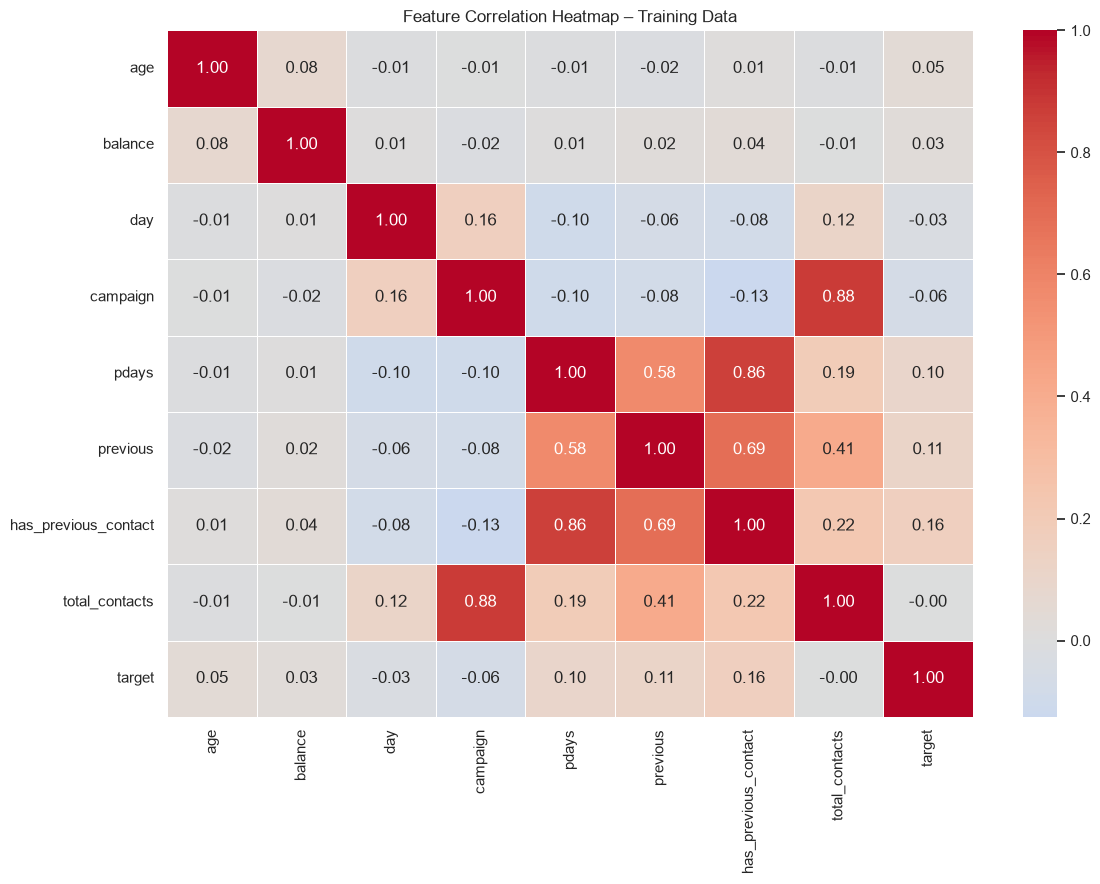

Saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/feature_engineering/01_feature_correlation.png


In [6]:
# Numerical features for correlation analysis
CORRELATION_FEATURES = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
    "has_previous_contact",
    "total_contacts",
]

correlation_data = X_train_engineered[
    CORRELATION_FEATURES
].copy()

# Add binary target for association inspection
correlation_data["target"] = y_train

# Calculate Pearson correlation
correlation_matrix = correlation_data.corr(method="pearson")

print("NUMERICAL FEATURE CORRELATION MATRIX")
display(correlation_matrix.round(3))

# Plot correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
)

plt.title("Feature Correlation Heatmap – Training Data")
plt.tight_layout()

correlation_path = IMAGE_PATH / "01_feature_correlation.png"
plt.savefig(correlation_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", correlation_path)

## 6. Feature Selection – Mutual Information

Mutual Information measures how much information a feature provides about the target variable.

It can identify potentially useful nonlinear and categorical relationships.

Methodology:
- Use training data only.
- Encode categorical variables using OrdinalEncoder fitted on training data.
- Treat categorical and discrete count variables as discrete.
- Treat age and balance as continuous numerical variables.
- Rank features by their Mutual Information scores.
- Do not use the validation target during feature selection.

MUTUAL INFORMATION FEATURE RANKING


,Feature,Mutual_Information
0,pdays,0.0634
1,poutcome,0.0262
2,month,0.0221
3,previous,0.0144
4,age,0.0113
5,has_previous_contact,0.0110
6,contact,0.0110
7,day,0.0107
8,age_group,0.0077
9,job,0.0075


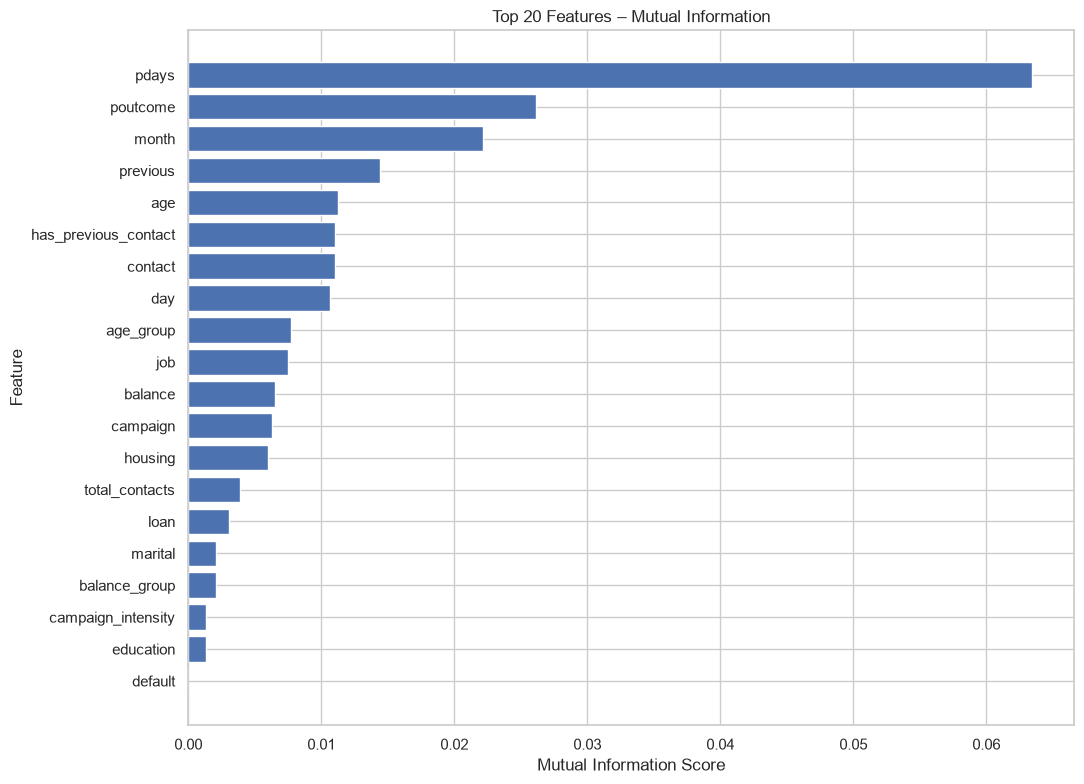

Saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/feature_engineering/02_mutual_information.png


In [7]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif

# --------------------------------------------------
# 1. Define numerical and categorical features
# --------------------------------------------------

MI_NUMERICAL_FEATURES = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
    "total_contacts",
]

MI_CATEGORICAL_FEATURES = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
    "age_group",
    "balance_group",
    "has_previous_contact",
    "campaign_intensity",
]

MI_FEATURES = (
    MI_NUMERICAL_FEATURES +
    MI_CATEGORICAL_FEATURES
)

# --------------------------------------------------
# 2. Prepare training features
# --------------------------------------------------

X_mi = X_train_engineered[MI_FEATURES].copy()

# Convert categorical columns into numeric codes.
# Encoder is fitted only on training data.
mi_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

X_mi[MI_CATEGORICAL_FEATURES] = mi_encoder.fit_transform(
    X_mi[MI_CATEGORICAL_FEATURES].astype(str)
)

# --------------------------------------------------
# 3. Define discrete feature mask
# --------------------------------------------------

DISCRETE_NUMERICAL_FEATURES = [
    "day",
    "campaign",
    "pdays",
    "previous",
    "total_contacts",
]

discrete_features = [
    feature in (
        MI_CATEGORICAL_FEATURES +
        DISCRETE_NUMERICAL_FEATURES
    )
    for feature in MI_FEATURES
]

# --------------------------------------------------
# 4. Calculate Mutual Information
# --------------------------------------------------

mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_features,
    random_state=RANDOM_STATE,
)

mi_results = pd.DataFrame({
    "Feature": MI_FEATURES,
    "Mutual_Information": mi_scores,
})

mi_results = mi_results.sort_values(
    "Mutual_Information",
    ascending=False,
).reset_index(drop=True)

print("MUTUAL INFORMATION FEATURE RANKING")
display(mi_results.round(4))

# --------------------------------------------------
# 5. Visualize top 20 features
# --------------------------------------------------

top_mi = mi_results.head(20).sort_values(
    "Mutual_Information",
    ascending=True,
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_mi["Feature"],
    top_mi["Mutual_Information"],
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.title("Top 20 Features – Mutual Information")

plt.tight_layout()

mi_path = IMAGE_PATH / "02_mutual_information.png"
plt.savefig(mi_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", mi_path)

## 7. Observations and Business Insights – Correlation and Mutual Information

### Correlation Analysis

**Observations:**
- Campaign and total_contacts have a strong positive correlation of approximately 0.877.
- Pdays and has_previous_contact have a strong positive correlation of approximately 0.864.
- Previous and has_previous_contact have a positive correlation of approximately 0.691.
- Pdays and previous have a moderate positive correlation of approximately 0.576.
- Most other numerical feature relationships are weak.

**Business Insights:**
- Total_contacts contains overlapping information because it is calculated using campaign and previous.
- Has_previous_contact represents information already related to pdays.
- Redundant features should be evaluated through model performance before removal.

### Mutual Information Analysis

**Observations:**
- Pdays has the highest Mutual Information score (0.0634).
- Poutcome (0.0262) and month (0.0221) are the next highest.
- Previous, age, has_previous_contact, and contact provide additional information.
- Age_group, balance_group, and campaign_intensity have lower scores than their corresponding original features.
- Default has a score of 0.0000 in this analysis.

**Business Insights:**
- Previous campaign history and contact timing may help identify customers more likely to subscribe.
- Grouping numerical variables does not necessarily improve predictive information.
- Mutual Information provides a screening ranking, not a final feature-selection decision.

### Feature Selection Decision

No features are removed at this stage. Final decisions will be based on Random Forest importance, permutation importance, and validation performance.

## 8. Random Forest Feature Importance

Random Forest feature importance helps identify which engineered and original features contribute most to the model's predictions.

We will:
- Train a Random Forest classifier using training data only.
- Calculate impurity-based feature importance.
- Rank features from most important to least important.
- Visualize the top 20 features.
- Save the feature-importance chart in the project images directory.

This analysis will support feature selection, but final decisions will also consider permutation importance and validation performance.

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group', 'balance_group', 'campaign_intensity']

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,balance,0.105902
1,age,0.091707
2,day,0.088660
3,total_contacts,0.040204
4,campaign,0.036300
...,...,...
60,month_sep,0.002428
61,default_no,0.001773
62,default_yes,0.001513
63,job_unknown,0.000643


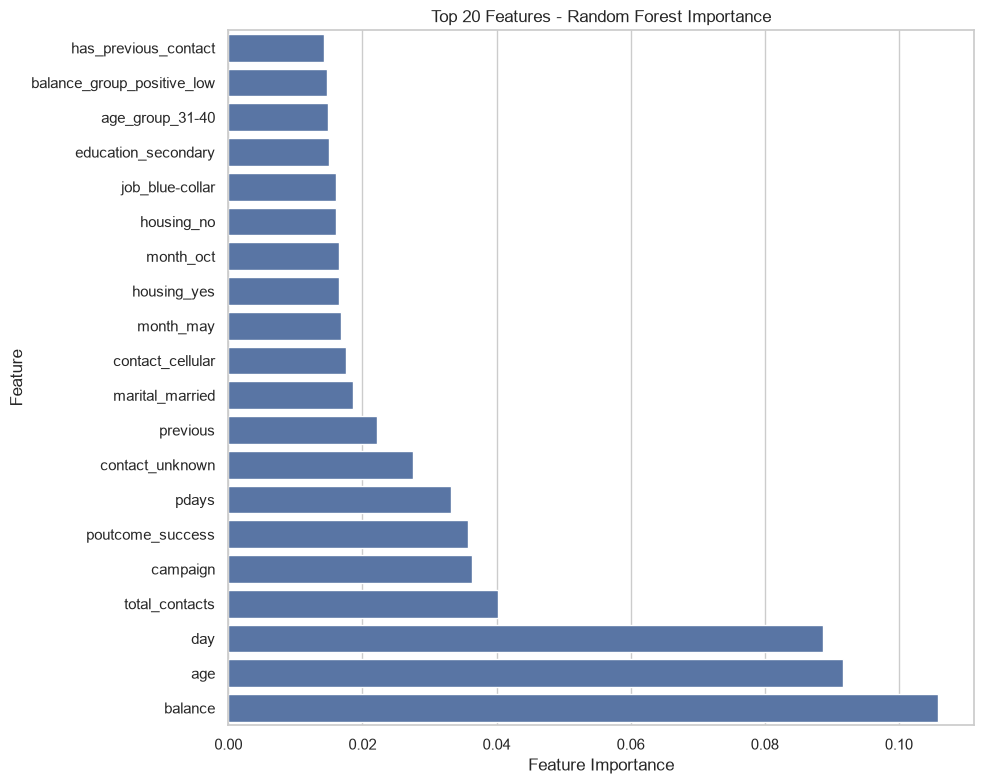


Encoded training shape: (3616, 65)
Saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/feature_engineering/03_random_forest_importance.png


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Identify categorical columns
categorical_columns = X_train_engineered.select_dtypes(
    include=["object", "str", "category", "string"]
).columns.tolist()

print("Categorical columns:", categorical_columns)

# One-hot encode training features
X_train_rf = pd.get_dummies(
    X_train_engineered,
    columns=categorical_columns,
    dtype=int
)

# Train Random Forest
rf_importance_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_importance_model.fit(X_train_rf, y_train)

# Extract feature importance
rf_importance = pd.DataFrame({
    "Feature": X_train_rf.columns,
    "Importance": rf_importance_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("\nRANDOM FOREST FEATURE IMPORTANCE")
display(rf_importance)

# Visualize top 20 features
top_rf_features = rf_importance.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_rf_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 20 Features - Random Forest Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

rf_figure_path = IMAGE_PATH / "03_random_forest_importance.png"

plt.savefig(
    rf_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEncoded training shape:", X_train_rf.shape)
print("Saved:", rf_figure_path)

## 9. Observations and Business Insights – Random Forest Feature Importance

### Observations

- Balance has the highest impurity-based importance (approximately 0.1059).
- Age is the second most important feature (approximately 0.0917).
- Day ranks third with an importance of approximately 0.0887.
- Total_contacts and campaign also contribute to model decisions.
- Poutcome_success, pdays and previous indicate the importance of previous campaign history.
- Several engineered categorical features appear among the top 20 features.

### Business Insights

- Customer financial balance and age may help distinguish customers with different subscription likelihoods.
- Contact timing and previous campaign history may provide useful predictive information.
- Campaign contact frequency should be evaluated carefully because excessive contacts may overlap with other contact-history features.
- Feature importance does not establish causation.
- Impurity-based importance alone is insufficient for final feature selection.

### Decision

No features are removed based only on Random Forest impurity-based importance. Permutation importance and validation performance will be considered before finalizing the feature set.

## 10. Permutation Feature Importance

Permutation importance evaluates the contribution of each feature by measuring the decrease in model performance when that feature is randomly shuffled.

Unlike impurity-based importance, this method evaluates feature importance using validation performance.

We will:
- Transform validation features using the same one-hot encoded columns as training data.
- Calculate permutation importance on validation data.
- Use Average Precision (PR-AUC) as the scoring metric.
- Rank and visualize the most important features.

PERMUTATION FEATURE IMPORTANCE


,Feature,Importance_Mean,Importance_Std
0,poutcome_success,0.069804,0.007990
1,poutcome_unknown,0.011802,0.004279
2,pdays,0.010793,0.004059
3,month_may,0.010385,0.005941
4,previous,0.008307,0.004810
5,has_previous_contact,0.007382,0.005160
6,month_jun,0.005535,0.003042
7,contact_unknown,0.005261,0.005383
8,education_primary,0.004485,0.002605
9,month_nov,0.004032,0.002192


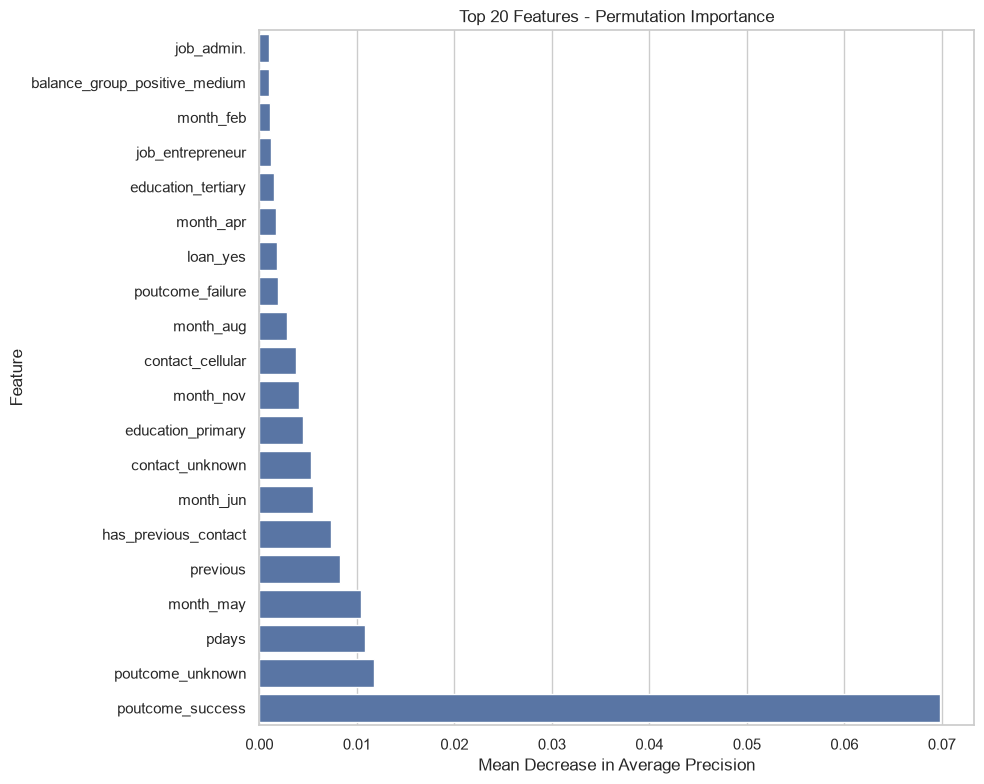

Validation feature shape: (905, 65)
Saved: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/feature_engineering/04_permutation_importance.png


In [9]:
from sklearn.inspection import permutation_importance

# One-hot encode validation data using the same categorical columns
X_valid_rf = pd.get_dummies(
    X_valid_engineered,
    columns=categorical_columns,
    dtype=int
)

# Align validation columns with training columns
X_valid_rf = X_valid_rf.reindex(
    columns=X_train_rf.columns,
    fill_value=0
)

# Calculate permutation importance on validation data
permutation_results = permutation_importance(
    rf_importance_model,
    X_valid_rf,
    y_valid,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create importance table
permutation_importance_df = pd.DataFrame({
    "Feature": X_valid_rf.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("PERMUTATION FEATURE IMPORTANCE")
display(permutation_importance_df.head(20))

# Visualize top 20 features
top_permutation_features = (
    permutation_importance_df.head(20)
    .sort_values(by="Importance_Mean", ascending=True)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_permutation_features,
    x="Importance_Mean",
    y="Feature"
)

plt.title("Top 20 Features - Permutation Importance")
plt.xlabel("Mean Decrease in Average Precision")
plt.ylabel("Feature")
plt.tight_layout()

permutation_figure_path = (
    IMAGE_PATH / "04_permutation_importance.png"
)

plt.savefig(
    permutation_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Validation feature shape:", X_valid_rf.shape)
print("Saved:", permutation_figure_path)

## 10. Observations and Business Insights – Permutation Importance

### Observations

- Poutcome_success has the highest permutation importance (0.0698).
- Poutcome_unknown ranks second with an importance of 0.0118.
- Pdays and previous also contribute useful predictive information.
- Month-related features such as month_may, month_jun and month_nov appear among the important features.
- Previous campaign history contributes substantially to validation PR-AUC.
- The permutation ranking differs from Random Forest impurity-based importance.

### Business Insights

- Previous campaign success is a strong indicator of customer subscription likelihood.
- Historical contact information can help prioritize potential customers.
- Campaign timing may influence subscription outcomes.
- Marketing teams can use campaign history and timing to improve customer targeting.
- Feature importance indicates predictive contribution, not causation.

### Feature Selection Decision

No features are removed at this stage.

Random Forest impurity importance and permutation importance will be considered together. Final feature selection will also depend on validation performance and the effect of removing potentially redundant features.

## 11. Feature Redundancy and Multicollinearity Analysis

This section identifies highly correlated numerical and engineered features.

The objective is to detect redundant information that may affect model simplicity and interpretability.

No features will be removed automatically. Any feature-selection decision will be validated through model performance.

In [10]:
# Identify numerical features in the engineered training dataset

numeric_features = X_train_engineered.select_dtypes(
    include=["number"]
).columns.tolist()

# Calculate correlation matrix
feature_corr = X_train_engineered[numeric_features].corr()

# Identify highly correlated feature pairs
high_corr_pairs = []

for i in range(len(feature_corr.columns)):
    for j in range(i + 1, len(feature_corr.columns)):

        feature_1 = feature_corr.columns[i]
        feature_2 = feature_corr.columns[j]

        correlation = feature_corr.iloc[i, j]

        if abs(correlation) >= 0.80:
            high_corr_pairs.append({
                "Feature 1": feature_1,
                "Feature 2": feature_2,
                "Correlation": round(correlation, 4)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

print("NUMERICAL FEATURES:")
print(numeric_features)

print("\nHIGHLY CORRELATED FEATURE PAIRS:")
if high_corr_df.empty:
    print("No pairs found with absolute correlation >= 0.80.")
else:
    display(
        high_corr_df.sort_values(
            by="Correlation",
            key=lambda x: x.abs(),
            ascending=False
        )
    )

NUMERICAL FEATURES:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'has_previous_contact', 'total_contacts']

HIGHLY CORRELATED FEATURE PAIRS:


,Feature 1,Feature 2,Correlation
0,campaign,total_contacts,0.8771
1,pdays,has_previous_contact,0.8638


## 12. Observations and Business Insights – Feature Redundancy

### Observations

- Campaign and total_contacts have a strong positive correlation of 0.8771.
- Pdays and has_previous_contact have a strong positive correlation of 0.8638.
- Total_contacts is derived from campaign and previous.
- Has_previous_contact represents information related to previous contact history.
- These relationships indicate overlapping information between engineered and original features.

### Business Insights

- Redundant features may increase model complexity without providing sufficient additional information.
- Removing unnecessary features may improve model simplicity and interpretability.
- Feature removal must be evaluated using validation performance.
- Tree-based models can handle correlated features, but their importance rankings may be distributed across related variables.

### Feature Selection Decision

No features are removed at this stage.

The identified feature pairs will be evaluated through controlled experiments during model development. The final decision will consider validation PR-AUC, precision, recall and F1-score.

## 13. Controlled Feature Set Comparison

Four feature configurations will be compared to investigate the impact of potentially redundant features.

- Experiment A: All engineered features.
- Experiment B: Remove total_contacts.
- Experiment C: Remove has_previous_contact.
- Experiment D: Remove both total_contacts and has_previous_contact.

All experiments will use the same training-validation split, model configuration and random state.

The comparison will use accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC.

No feature set will be selected until validation results are compared.


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Define feature sets
feature_sets = {
    "A_Full_Features": [],
    "B_Without_Total_Contacts": ["total_contacts"],
    "C_Without_Previous_Contact_Flag": ["has_previous_contact"],
    "D_Without_Both": [
        "total_contacts",
        "has_previous_contact"
    ]
}

comparison_results = []

for experiment_name, columns_to_remove in feature_sets.items():

    # Create experiment-specific datasets
    X_train_exp = X_train_engineered.drop(
        columns=columns_to_remove
    )

    X_valid_exp = X_valid_engineered.drop(
        columns=columns_to_remove
    )

    # Identify column types
    numeric_columns = X_train_exp.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_columns = X_train_exp.select_dtypes(
        include=["object", "category", "str"]
    ).columns.tolist()

    # Preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_columns
            ),
            (
                "numerical",
                "passthrough",
                numeric_columns
            )
        ]
    )

    # Complete model pipeline
    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=300,
                    max_depth=12,
                    min_samples_split=5,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ]
    )

    # Train
    model_pipeline.fit(X_train_exp, y_train)

    # Predict
    y_pred = model_pipeline.predict(X_valid_exp)
    y_prob = model_pipeline.predict_proba(X_valid_exp)[:, 1]

    # Evaluate
    comparison_results.append({
        "Experiment": experiment_name,
        "Input_Features": X_train_exp.shape[1],
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(
            y_valid, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, y_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_valid, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_valid, y_prob),
        "PR_AUC": average_precision_score(y_valid, y_prob)
    })

# Display comparison
feature_comparison_df = pd.DataFrame(comparison_results)

display(
    feature_comparison_df.round(4).sort_values(
        by="PR_AUC",
        ascending=False
    )
)

,Experiment,Input_Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
1,B_Without_Total_Contacts,19,0.8188,0.2973,0.4231,0.3492,0.7521,0.3432
3,D_Without_Both,18,0.8254,0.3291,0.5000,0.3969,0.7574,0.3397
0,A_Full_Features,20,0.8210,0.3041,0.4327,0.3571,0.7506,0.3387
2,C_Without_Previous_Contact_Flag,19,0.8188,0.3052,0.4519,0.3643,0.7494,0.3385


### 13. Feature Redundancy Experiment – Observations and Business Insights

**Observations:**

- The full-feature experiment achieved a PR-AUC of 0.3387 and F1-score of 0.3571.
- Removing `total_contacts` produced the highest PR-AUC of 0.3432.
- Removing `has_previous_contact` improved recall to 0.4519.
- Removing both features achieved the highest recall (0.5000) and F1-score (0.3969).
- The performance differences across the four experiments are relatively small.

**Business Insights:**

- Removing redundant features may simplify the model without substantially reducing predictive performance.
- Higher recall can help identify more potential subscribers, reducing missed marketing opportunities.
- The appropriate feature set depends on the business objective and the trade-off between precision and recall.
- Feature selection should be validated using cross-validation and consistent evaluation metrics.

**Feature Selection Decision:**

No final features will be removed based only on this single validation split. The four experiments will be considered during model development, and the final feature set will be selected using cross-validation and validation performance.